# Numerical Solution of Ordinary Differential Equations: Euler, Improved Euler, and Runge–Kutta Methods

**Author:** Taimoor Ali  
**Date:** October 2026  
**Course Context:** Numerical Analysis / Computational Mathematics

---

## 1. Problem Statement

We consider the initial value problem (IVP)

$$\frac{dy}{dt} = f(t, y), \quad y(t_0) = y_0,$$

where $f: \mathbb{R} \times \mathbb{R} \to \mathbb{R}$ is a given function. The goal is to approximate the solution $y(t)$ at discrete time levels $t_0 < t_1 < \cdots < t_N$ using a constant step size $h = t_{n+1} - t_n$.

This notebook implements three single-step methods of increasing sophistication:

1. **Euler's Method** (forward Euler) — a first-order explicit scheme.
2. **Improved Euler Method** (Heun's method) — a second-order explicit Runge–Kutta scheme.
3. **Classical Runge–Kutta Method (RK4)** — the fourth-order scheme that is the workhorse of practical ODE computation.

For each method, we derive the update formula, discuss its local and global truncation error, implement it from scratch, and verify the convergence order on test problems with known analytical solutions.

## 2. Mathematical Background

### 2.1 Euler's Method

The simplest approach is to discretise the derivative by a forward difference. Starting from the definition $y'(t_n) = \lim_{h \to 0} \frac{y(t_n + h) - y(t_n)}{h}$, we drop the limit and replace the derivative with the right-hand side of the ODE:

$$y_{n+1} = y_n + h \, f(t_n, y_n).$$

**Local truncation error (LTE).** Expanding $y(t_{n+1})$ in a Taylor series about $t_n$:

$$y(t_{n+1}) = y(t_n) + h\, y'(t_n) + \frac{h^2}{2} y''(t_n) + O(h^3).$$

The Euler step captures the first two terms exactly, so the local error per step is $O(h^2)$. Over the interval $[t_0, T]$ with $N = (T - t_0)/h$ steps, the accumulated **global truncation error** is $O(h)$, making Euler a first-order method.

### 2.2 Improved Euler (Heun's Method)

Heun's method is a predictor–corrector scheme. It first predicts an intermediate value using a forward Euler step and then corrects by averaging the slopes at both endpoints of the interval:

$$\tilde{y}_{n+1} = y_n + h\, f(t_n, y_n) \quad \text{(predictor)}$$
$$y_{n+1} = y_n + \frac{h}{2} \bigl[ f(t_n, y_n) + f(t_{n+1}, \tilde{y}_{n+1}) \bigr] \quad \text{(corrector)}.$$

This is equivalent to a two-stage Runge–Kutta method with Butcher tableau

$$\begin{array}{c|cc} 0 & & \\ 1 & 1 & \\ \hline & \frac{1}{2} & \frac{1}{2} \end{array}$$

The LTE is $O(h^3)$ and the global error is $O(h^2)$: a second-order method.

### 2.3 Classical Runge–Kutta (RK4)

The most widely used member of the Runge–Kutta family evaluates the slope at four carefully chosen points within each step:

$$k_1 = f(t_n, y_n)$$
$$k_2 = f\!\left(t_n + \frac{h}{2},\, y_n + \frac{h}{2} k_1\right)$$
$$k_3 = f\!\left(t_n + \frac{h}{2},\, y_n + \frac{h}{2} k_2\right)$$
$$k_4 = f(t_n + h,\, y_n + h\, k_3)$$
$$y_{n+1} = y_n + \frac{h}{6}(k_1 + 2k_2 + 2k_3 + k_4).$$

The Butcher tableau is

$$\begin{array}{c|cccc} 0 & & & & \\ \frac{1}{2} & \frac{1}{2} & & & \\ \frac{1}{2} & 0 & \frac{1}{2} & & \\ 1 & 0 & 0 & 1 & \\ \hline & \frac{1}{6} & \frac{1}{3} & \frac{1}{3} & \frac{1}{6} \end{array}$$

The method matches the Taylor expansion through the $h^4$ term, giving LTE $= O(h^5)$ and global error $= O(h^4)$. It uses four function evaluations per step.

## 3. Test Problems

We select IVPs whose exact solutions are available in closed form.

| Problem | ODE | Initial Condition | Exact Solution | Character |
|---------|-----|-------------------|----------------|----------|
| P1 | $y' = -2y$ | $y(0) = 1$ | $y(t) = e^{-2t}$ | Exponential decay (linear, stiff if $h$ large) |
| P2 | $y' = y - t^2 + 1$ | $y(0) = 0.5$ | $y(t) = (t+1)^2 - 0.5 e^t$ | Nonlinear interaction; classic textbook problem |
| P3 | $y' = -y + \sin(t)$ | $y(0) = 1$ | $y(t) = \frac{1}{2}(\sin t - \cos t) + \frac{3}{2}e^{-t}$ | Oscillatory forcing with transient decay |

In [1]:
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams.update({
    'figure.figsize': (10, 6),
    'font.size': 12,
    'axes.grid': True,
    'grid.alpha': 0.3,
    'lines.linewidth': 1.8
})

# ── Test problems ──

problems = [
    {
        'name': r"$y' = -2y$, $y(0) = 1$",
        'f': lambda t, y: -2 * y,
        'y0': 1.0,
        't_span': (0, 5),
        'exact': lambda t: np.exp(-2 * t),
        'label': 'Exponential decay'
    },
    {
        'name': r"$y' = y - t^2 + 1$, $y(0) = 0.5$",
        'f': lambda t, y: y - t**2 + 1,
        'y0': 0.5,
        't_span': (0, 2),
        'exact': lambda t: (t + 1)**2 - 0.5 * np.exp(t),
        'label': 'Polynomial-exponential'
    },
    {
        'name': r"$y' = -y + \sin(t)$, $y(0) = 1$",
        'f': lambda t, y: -y + np.sin(t),
        'y0': 1.0,
        't_span': (0, 10),
        'exact': lambda t: 0.5 * (np.sin(t) - np.cos(t)) + 1.5 * np.exp(-t),
        'label': 'Damped oscillation'
    }
]

# Verify the exact solutions at t = 0
for p in problems:
    t0 = p['t_span'][0]
    print(f"{p['label']:>25s}:  y_exact({t0}) = {p['exact'](t0):.6f},  y0 = {p['y0']:.6f}")

        Exponential decay:  y_exact(0) = 1.000000,  y0 = 1.000000
   Polynomial-exponential:  y_exact(0) = 0.500000,  y0 = 0.500000
       Damped oscillation:  y_exact(0) = 1.000000,  y0 = 1.000000


## 4. Implementations

All three solvers share a common interface: they take the right-hand side function $f(t, y)$, the initial condition $(t_0, y_0)$, the final time $T$, and the number of steps $N$. Each returns arrays of the time levels and the computed solution values.

In [2]:
def euler(f, t0, y0, T, N):
    """
    Forward Euler method for dy/dt = f(t, y).
    
    Parameters
    ----------
    f : callable(t, y) -> float
        Right-hand side of the ODE.
    t0, y0 : float
        Initial condition: y(t0) = y0.
    T : float
        Final time.
    N : int
        Number of time steps.
    
    Returns
    -------
    t_arr, y_arr : ndarray
        Time levels and computed solution values.
    """
    h = (T - t0) / N
    t_arr = np.linspace(t0, T, N + 1)
    y_arr = np.zeros(N + 1)
    y_arr[0] = y0
    
    for n in range(N):
        y_arr[n + 1] = y_arr[n] + h * f(t_arr[n], y_arr[n])
    
    return t_arr, y_arr


def improved_euler(f, t0, y0, T, N):
    """
    Improved Euler (Heun's) method for dy/dt = f(t, y).
    
    Uses a predictor-corrector approach:
      Predictor:  y_tilde = y_n + h * f(t_n, y_n)
      Corrector:  y_{n+1} = y_n + (h/2) * [f(t_n, y_n) + f(t_{n+1}, y_tilde)]
    """
    h = (T - t0) / N
    t_arr = np.linspace(t0, T, N + 1)
    y_arr = np.zeros(N + 1)
    y_arr[0] = y0
    
    for n in range(N):
        k1 = f(t_arr[n], y_arr[n])
        y_pred = y_arr[n] + h * k1
        k2 = f(t_arr[n + 1], y_pred)
        y_arr[n + 1] = y_arr[n] + (h / 2.0) * (k1 + k2)
    
    return t_arr, y_arr


def rk4(f, t0, y0, T, N):
    """
    Classical fourth-order Runge-Kutta method for dy/dt = f(t, y).
    
    Uses four slope evaluations per step:
      k1 = f(t_n, y_n)
      k2 = f(t_n + h/2, y_n + h/2 * k1)
      k3 = f(t_n + h/2, y_n + h/2 * k2)
      k4 = f(t_n + h, y_n + h * k3)
      y_{n+1} = y_n + (h/6)(k1 + 2*k2 + 2*k3 + k4)
    """
    h = (T - t0) / N
    t_arr = np.linspace(t0, T, N + 1)
    y_arr = np.zeros(N + 1)
    y_arr[0] = y0
    
    for n in range(N):
        tn = t_arr[n]
        yn = y_arr[n]
        
        k1 = f(tn, yn)
        k2 = f(tn + h / 2, yn + h / 2 * k1)
        k3 = f(tn + h / 2, yn + h / 2 * k2)
        k4 = f(tn + h, yn + h * k3)
        
        y_arr[n + 1] = yn + (h / 6.0) * (k1 + 2*k2 + 2*k3 + k4)
    
    return t_arr, y_arr

# Quick sanity check: solve P1 with RK4
t_test, y_test = rk4(problems[0]['f'], 0, 1.0, 5, 100)
y_exact_test = problems[0]['exact'](t_test)
print(f"RK4 max error on P1 (N=100): {np.max(np.abs(y_test - y_exact_test)):.6e}")

RK4 max error on P1 (N=100): 3.332411e-07


## 5. Solution Trajectories

We first compare the numerical solutions against the exact solutions at a moderate step size ($N = 20$) to visualise how each method performs.

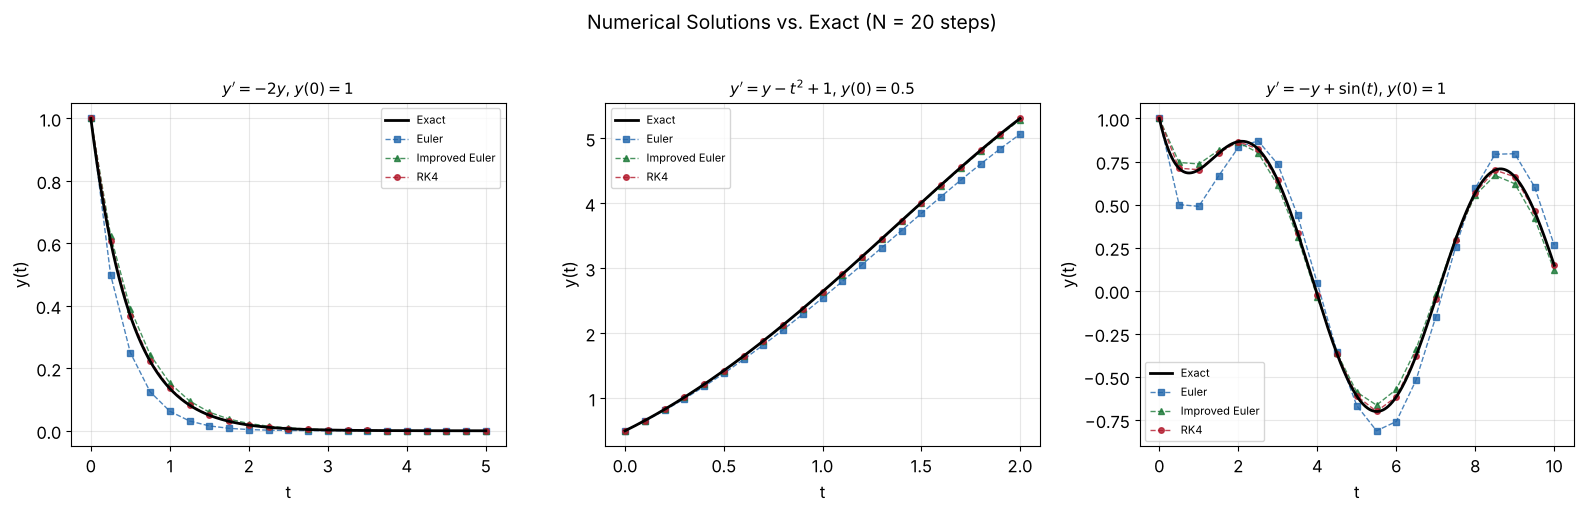

In [3]:
methods = [
    ('Euler', euler, '#2166ac', 's'),
    ('Improved Euler', improved_euler, '#1b7837', '^'),
    ('RK4', rk4, '#b2182b', 'o')
]

N_vis = 20

fig, axes = plt.subplots(1, 3, figsize=(16, 5))

for ax, prob in zip(axes, problems):
    t0, T = prob['t_span']
    t_fine = np.linspace(t0, T, 500)
    
    # Exact solution
    ax.plot(t_fine, prob['exact'](t_fine), 'k-', linewidth=2, label='Exact', zorder=5)
    
    # Numerical solutions
    for name, solver, colour, marker in methods:
        t_num, y_num = solver(prob['f'], t0, prob['y0'], T, N_vis)
        ax.plot(t_num, y_num, color=colour, marker=marker, markersize=4,
                linewidth=1, linestyle='--', label=name, alpha=0.8)
    
    ax.set_title(prob['name'], fontsize=11)
    ax.set_xlabel('t')
    ax.set_ylabel('y(t)')
    ax.legend(fontsize=8)

plt.suptitle(f'Numerical Solutions vs. Exact (N = {N_vis} steps)', fontsize=14, y=1.02)
plt.tight_layout()
plt.savefig('../figures/ode_trajectories.png', dpi=150, bbox_inches='tight')
plt.show()

## 6. Convergence Study

We measure the global error at the final time $T$ for each method across a range of step counts $N = 10, 20, 40, \ldots, 5120$. The theoretical predictions are:

- **Euler:** global error $\propto h = O(N^{-1})$
- **Improved Euler:** global error $\propto h^2 = O(N^{-2})$
- **RK4:** global error $\propto h^4 = O(N^{-4})$

We compute the observed convergence rate from successive refinements:

$$\hat{p} = \log_2 \left( \frac{E_N}{E_{2N}} \right).$$

In [4]:
N_values = [10, 20, 40, 80, 160, 320, 640, 1280, 2560, 5120]

convergence_data = {}

for prob in problems:
    label = prob['label']
    t0, T = prob['t_span']
    convergence_data[label] = {}
    
    print(f"\n{'='*80}")
    print(f"Problem: {prob['name']}")
    print(f"{'='*80}")
    print(f"{'N':>6s}  {'h':>12s}  {'Euler Err':>12s}  {'Rate':>6s}  "
          f"{'IE Err':>12s}  {'Rate':>6s}  {'RK4 Err':>12s}  {'Rate':>6s}")
    print('-' * 80)
    
    prev_errors = {name: None for name, _, _, _ in methods}
    
    for name, solver, _, _ in methods:
        convergence_data[label][name] = {'errors': [], 'h_values': []}
    
    for N in N_values:
        h = (T - t0) / N
        line = f"{N:6d}  {h:12.6f}"
        
        for name, solver, _, _ in methods:
            t_num, y_num = solver(prob['f'], t0, prob['y0'], T, N)
            y_exact_T = prob['exact'](T)
            err = abs(y_num[-1] - y_exact_T)
            
            convergence_data[label][name]['errors'].append(err)
            convergence_data[label][name]['h_values'].append(h)
            
            rate = '--'
            if prev_errors[name] is not None and err > 0:
                rate = f"{np.log2(prev_errors[name] / err):.2f}"
            prev_errors[name] = err
            
            line += f"  {err:12.4e}  {rate:>6s}"
        
        print(line)


Problem: $y' = -2y$, $y(0) = 1$
     N             h     Euler Err    Rate        IE Err    Rate       RK4 Err    Rate
--------------------------------------------------------------------------------
    10      0.500000    4.5400e-05      --    9.3116e-04      --    9.5937e-06      --
    20      0.250000    4.4446e-05    0.03    3.7318e-05    4.64    3.6090e-07    4.73
    40      0.125000    3.5343e-05    0.33    6.0756e-06    2.62    1.8216e-08    4.31
    80      0.062500    2.2457e-05    0.65    1.3174e-06    2.21    1.0252e-09    4.15
   160      0.031250    1.2635e-05    0.83    3.1083e-07    2.08    6.0818e-11    4.08
   320      0.015625    6.6965e-06    0.92    7.5710e-08    2.04    3.7033e-12    4.04
   640      0.007812    3.4464e-06    0.96    1.8695e-08    2.02    2.2846e-13    4.02
  1280      0.003906    1.7482e-06    0.98    4.6457e-09    2.01    1.4186e-14    4.01
  2560      0.001953    8.8039e-07    0.99    1.1580e-09    2.00    8.8377e-16    4.00
  5120      0.00

### 6.1 Log-Log Convergence Plots

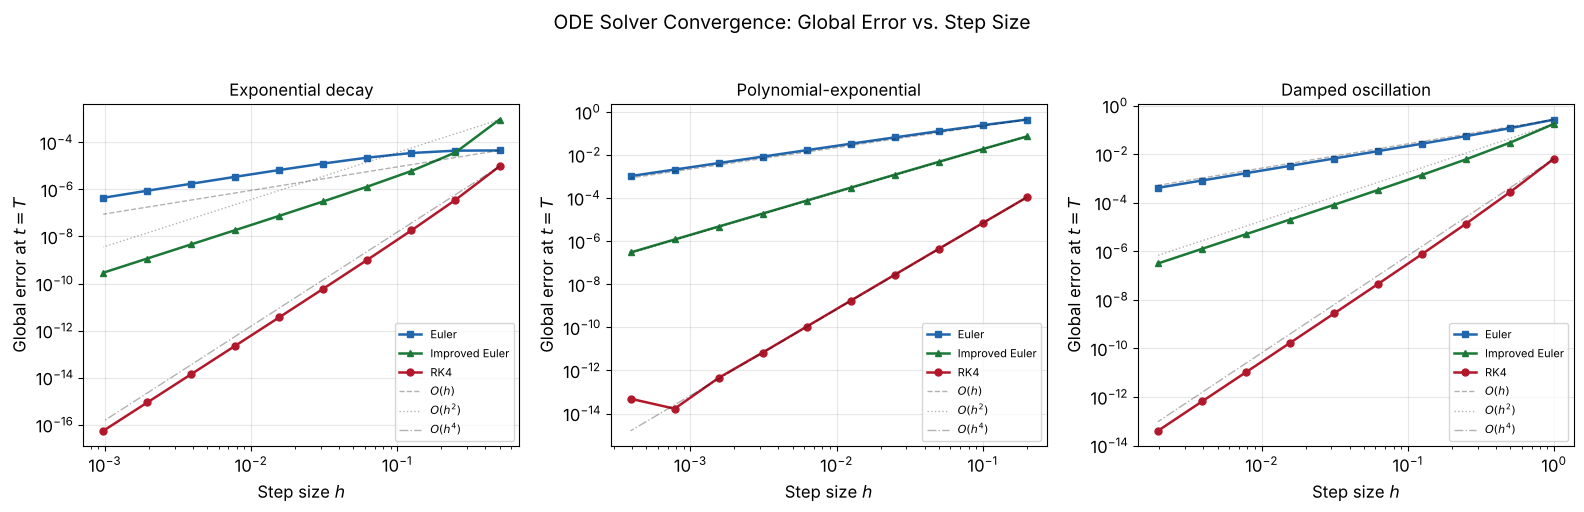

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

for ax, prob in zip(axes, problems):
    label = prob['label']
    data = convergence_data[label]
    
    for name, _, colour, marker in methods:
        h_arr = np.array(data[name]['h_values'])
        err_arr = np.array(data[name]['errors'])
        mask = err_arr > 0
        ax.loglog(h_arr[mask], err_arr[mask], color=colour, marker=marker,
                  markersize=5, label=name)
    
    # Reference slopes
    h_ref = np.array([h_arr[0], h_arr[-1]])
    euler_errs = np.array(data['Euler']['errors'])
    if euler_errs[0] > 0:
        c1 = euler_errs[0] / h_arr[0]
        ax.loglog(h_ref, c1 * h_ref, 'k--', alpha=0.3, linewidth=1, label=r'$O(h)$')
    
    ie_errs = np.array(data['Improved Euler']['errors'])
    if ie_errs[0] > 0:
        c2 = ie_errs[0] / h_arr[0]**2
        ax.loglog(h_ref, c2 * h_ref**2, 'k:', alpha=0.3, linewidth=1, label=r'$O(h^2)$')
    
    rk_errs = np.array(data['RK4']['errors'])
    if rk_errs[0] > 0:
        c4 = rk_errs[0] / h_arr[0]**4
        ax.loglog(h_ref, c4 * h_ref**4, 'k-.', alpha=0.3, linewidth=1, label=r'$O(h^4)$')
    
    ax.set_title(prob['label'], fontsize=12)
    ax.set_xlabel(r'Step size $h$')
    ax.set_ylabel('Global error at $t = T$')
    ax.legend(fontsize=8)

plt.suptitle('ODE Solver Convergence: Global Error vs. Step Size', fontsize=14, y=1.02)
plt.tight_layout()
plt.savefig('../figures/ode_convergence.png', dpi=150, bbox_inches='tight')
plt.show()

## 7. Stability Analysis

### 7.1 The Dahlquist Test Equation

The stability of a numerical method is conventionally analysed on the scalar test equation

$$y' = \lambda y, \quad \lambda \in \mathbb{C}, \quad \text{Re}(\lambda) < 0.$$

For each method, we define the **amplification factor** $R(z)$ where $z = h\lambda$, so that $y_{n+1} = R(z)\, y_n$. The method is stable when $|R(z)| \leq 1$.

- **Euler:** $R(z) = 1 + z$. Stable when $|1 + z| \leq 1$, a disc of radius 1 centred at $(-1, 0)$.
- **Improved Euler:** $R(z) = 1 + z + \frac{z^2}{2}$.
- **RK4:** $R(z) = 1 + z + \frac{z^2}{2} + \frac{z^3}{6} + \frac{z^4}{24}$ (the partial sum of $e^z$).

We plot the **stability region** $\{z \in \mathbb{C} : |R(z)| \leq 1\}$ for each method.

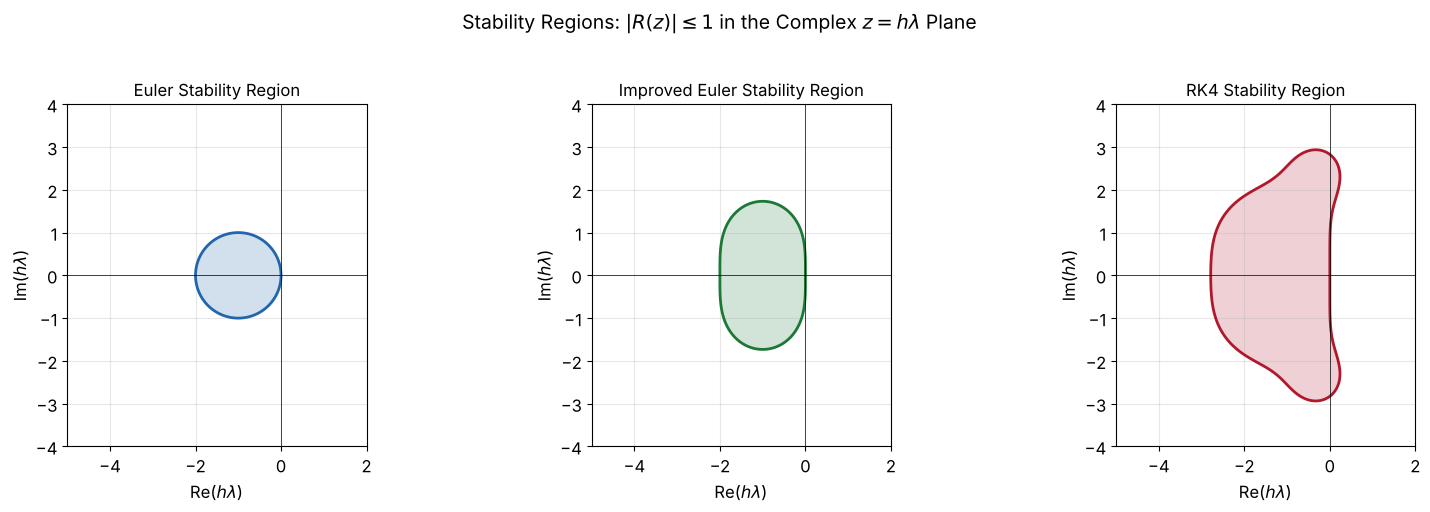

In [6]:
# Amplification factors
def R_euler(z):
    return 1 + z

def R_heun(z):
    return 1 + z + z**2 / 2

def R_rk4(z):
    return 1 + z + z**2 / 2 + z**3 / 6 + z**4 / 24

# Create a grid in the complex plane
x = np.linspace(-5, 2, 500)
y = np.linspace(-4, 4, 500)
X, Y = np.meshgrid(x, y)
Z = X + 1j * Y

fig, axes = plt.subplots(1, 3, figsize=(16, 5))

for ax, (name, R_func, colour) in zip(axes, [
    ('Euler', R_euler, '#2166ac'),
    ('Improved Euler', R_heun, '#1b7837'),
    ('RK4', R_rk4, '#b2182b')
]):
    amp = np.abs(R_func(Z))
    
    # Shade the stability region
    ax.contourf(X, Y, amp, levels=[0, 1], colors=[colour], alpha=0.2)
    ax.contour(X, Y, amp, levels=[1], colors=[colour], linewidths=2)
    
    ax.axhline(y=0, color='k', linewidth=0.5)
    ax.axvline(x=0, color='k', linewidth=0.5)
    ax.set_title(f'{name} Stability Region', fontsize=12)
    ax.set_xlabel(r'Re($h\lambda$)')
    ax.set_ylabel(r'Im($h\lambda$)')
    ax.set_aspect('equal')
    ax.set_xlim(-5, 2)
    ax.set_ylim(-4, 4)

plt.suptitle(r'Stability Regions: $|R(z)| \leq 1$ in the Complex $z = h\lambda$ Plane',
             fontsize=14, y=1.02)
plt.tight_layout()
plt.savefig('../figures/stability_regions.png', dpi=150, bbox_inches='tight')
plt.show()

### 7.2 Stability Demonstration

To illustrate what happens outside the stability region, we solve the decay equation $y' = -10\,y$ (a mildly stiff problem) with Euler's method at two different step sizes: one inside the stability region ($h = 0.15$, so $z = -1.5$, inside the disc $|1+z| \leq 1$) and one outside it ($h = 0.25$, so $z = -2.5$, outside the disc).

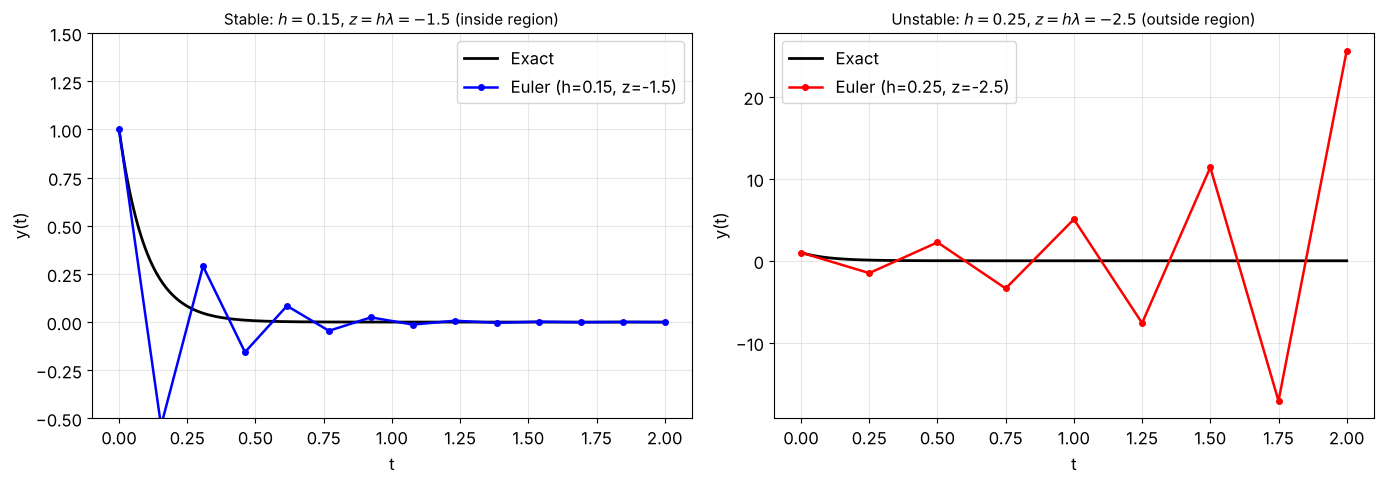

In [7]:
lam = -10
f_stiff = lambda t, y: lam * y
exact_stiff = lambda t: np.exp(lam * t)

T_stiff = 2.0

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

t_fine = np.linspace(0, T_stiff, 500)

# Case 1: h = 0.15, z = h*lambda = -1.5 (inside stability region)
h1 = 0.15
N1 = int(T_stiff / h1)
t1, y1 = euler(f_stiff, 0, 1.0, T_stiff, N1)

ax1.plot(t_fine, exact_stiff(t_fine), 'k-', linewidth=2, label='Exact')
ax1.plot(t1, y1, 'b-o', markersize=4, label=f'Euler (h={h1}, z={h1*lam:.1f})')
ax1.set_title(f'Stable: $h={h1}$, $z = h\\lambda = {h1*lam:.1f}$ (inside region)', fontsize=11)
ax1.set_xlabel('t')
ax1.set_ylabel('y(t)')
ax1.legend()
ax1.set_ylim(-0.5, 1.5)

# Case 2: h = 0.25, z = h*lambda = -2.5 (outside stability region)
h2 = 0.25
N2 = int(T_stiff / h2)
t2, y2 = euler(f_stiff, 0, 1.0, T_stiff, N2)

ax2.plot(t_fine, exact_stiff(t_fine), 'k-', linewidth=2, label='Exact')
ax2.plot(t2, y2, 'r-o', markersize=4, label=f'Euler (h={h2}, z={h2*lam:.1f})')
ax2.set_title(f'Unstable: $h={h2}$, $z = h\\lambda = {h2*lam:.1f}$ (outside region)', fontsize=11)
ax2.set_xlabel('t')
ax2.set_ylabel('y(t)')
ax2.legend()

plt.tight_layout()
plt.savefig('../figures/stability_demo.png', dpi=150, bbox_inches='tight')
plt.show()

## 8. Error Accumulation Over Time

An important practical concern is how the error grows over the integration interval. For non-stiff problems, the global error typically grows at a rate proportional to $e^{L(t - t_0)}$ where $L$ is the Lipschitz constant of $f$ with respect to $y$. Here we plot $|y_n - y(t_n)|$ at every grid point, not just at the final time.

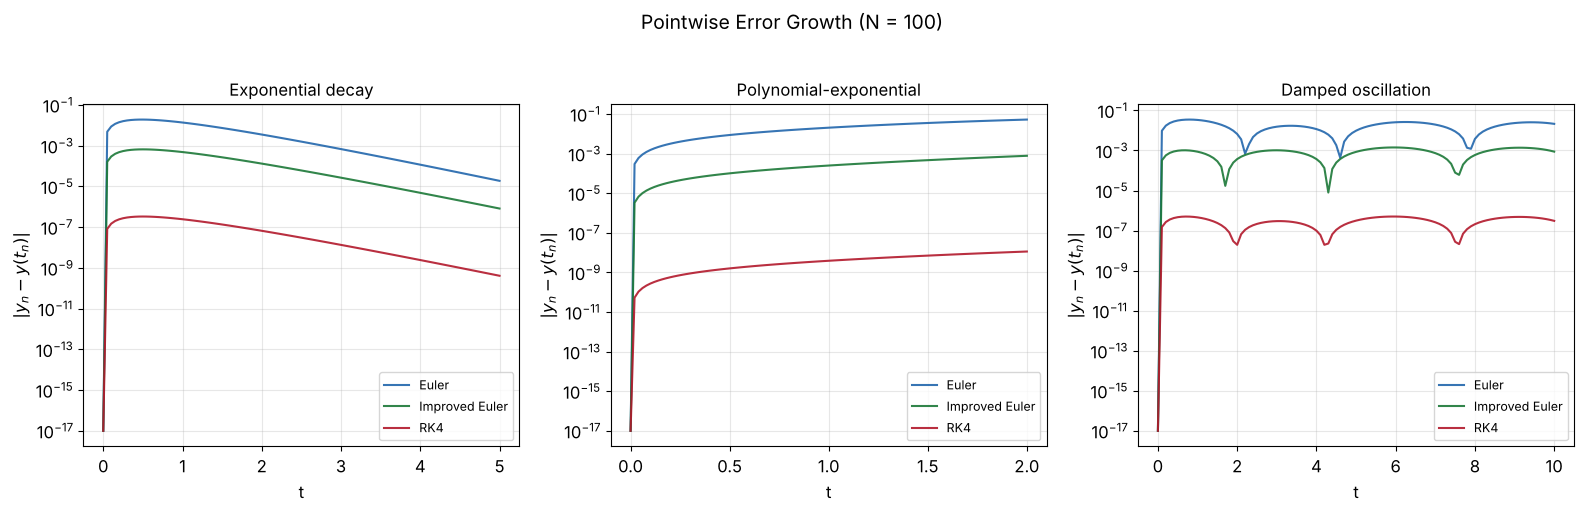

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

N_err = 100

for ax, prob in zip(axes, problems):
    t0, T = prob['t_span']
    
    for name, solver, colour, marker in methods:
        t_num, y_num = solver(prob['f'], t0, prob['y0'], T, N_err)
        y_exact_arr = prob['exact'](t_num)
        pointwise_err = np.abs(y_num - y_exact_arr)
        
        ax.semilogy(t_num, pointwise_err + 1e-17, color=colour, linewidth=1.5,
                    label=name, alpha=0.9)
    
    ax.set_title(prob['label'], fontsize=12)
    ax.set_xlabel('t')
    ax.set_ylabel(r'$|y_n - y(t_n)|$')
    ax.legend(fontsize=9)

plt.suptitle(f'Pointwise Error Growth (N = {N_err})', fontsize=14, y=1.02)
plt.tight_layout()
plt.savefig('../figures/error_accumulation.png', dpi=150, bbox_inches='tight')
plt.show()

## 9. Computational Cost Comparison

Each method requires a different number of right-hand side evaluations per step:

| Method | $f$-evaluations per step |
|--------|:-:|
| Euler | 1 |
| Improved Euler | 2 |
| RK4 | 4 |

Thus, for a fair comparison, we should plot the error against the total number of function evaluations rather than the number of steps. At $N$ steps, the total evaluations are $N$, $2N$, and $4N$ respectively.

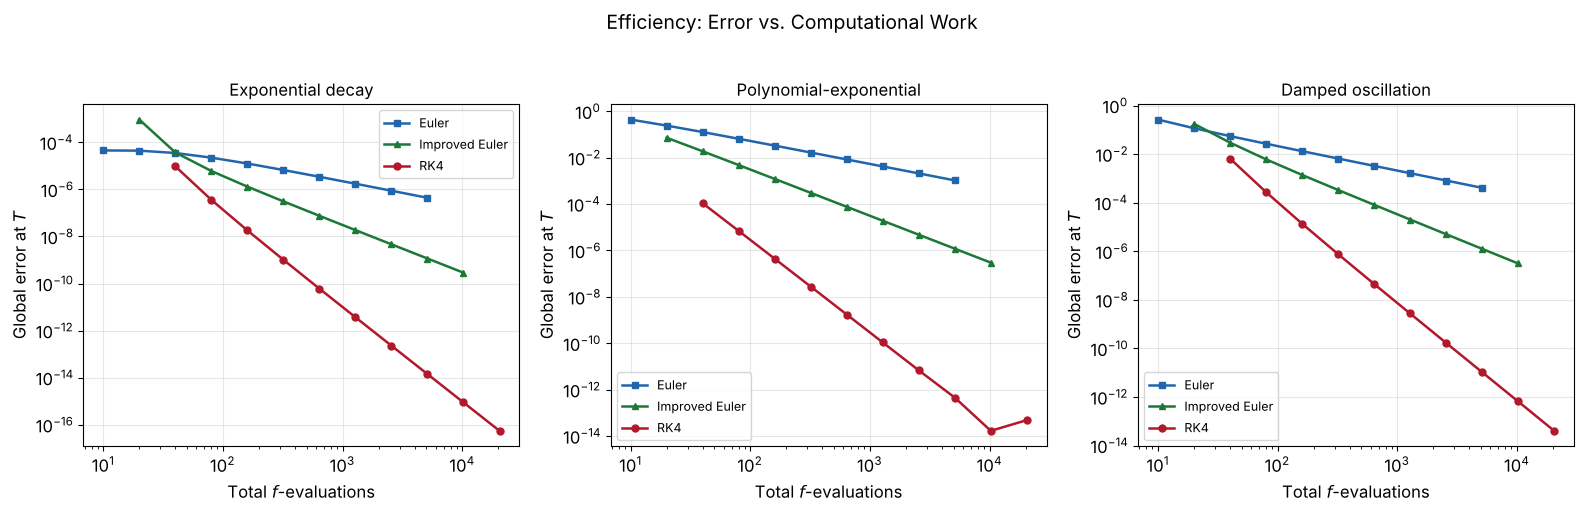

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

evals_per_step = {'Euler': 1, 'Improved Euler': 2, 'RK4': 4}

for ax, prob in zip(axes, problems):
    label = prob['label']
    data = convergence_data[label]
    
    for name, _, colour, marker in methods:
        errs = np.array(data[name]['errors'])
        total_evals = np.array(N_values) * evals_per_step[name]
        mask = errs > 0
        ax.loglog(total_evals[mask], errs[mask], color=colour, marker=marker,
                  markersize=5, label=name)
    
    ax.set_title(prob['label'], fontsize=12)
    ax.set_xlabel('Total $f$-evaluations')
    ax.set_ylabel('Global error at $T$')
    ax.legend(fontsize=9)

plt.suptitle('Efficiency: Error vs. Computational Work', fontsize=14, y=1.02)
plt.tight_layout()
plt.savefig('../figures/ode_efficiency.png', dpi=150, bbox_inches='tight')
plt.show()

## 10. Summary of Findings

| Method | Global Error Order | $f$-evals/step | Stability Region Size | Memory |
|--------|:-:|:-:|:-:|:-:|
| Euler | $O(h)$ | 1 | Small disc | 1 stage |
| Improved Euler | $O(h^2)$ | 2 | Moderate | 2 stages |
| RK4 | $O(h^4)$ | 4 | Large | 4 stages |

**Key observations:**

1. The observed convergence rates match the theoretical predictions across all three test problems: Euler converges as $O(h)$, Improved Euler as $O(h^2)$, and RK4 as $O(h^4)$.

2. When cost is measured in function evaluations rather than steps, RK4 is far more efficient than the lower-order methods. To achieve a global error of $10^{-8}$, Euler might need millions of steps, Improved Euler needs thousands, and RK4 typically needs only a few hundred.

3. The stability analysis reveals that each higher-order method has a larger stability region along the negative real axis, permitting larger step sizes on stiff problems. However, all three explicit methods have bounded stability regions, which means they are ultimately unsuitable for very stiff systems — implicit methods (backward Euler, trapezoidal rule, implicit Runge–Kutta) are required in that regime.

4. The stability demonstration on $y' = -10y$ shows that choosing $h$ outside the stability boundary produces oscillations that grow without bound, even though the exact solution decays monotonically. This underlines the practical importance of the stability constraint in selecting step sizes.

5. The error accumulation plots show that for stable problems, the error grows smoothly and remains bounded, consistent with the Lipschitz theory of error propagation.

**Possible extensions.** Adaptive step-size control (such as the Runge–Kutta–Fehlberg 4(5) pair) adjusts $h$ at each step to maintain a specified local error tolerance, yielding near-optimal efficiency. For stiff systems, the backward differentiation formulae (BDF methods) or implicit Runge–Kutta methods provide unconditional stability at the cost of solving a nonlinear system at each step.

---

## References

1. Burden, R. L., & Faires, J. D. (2010). *Numerical Analysis* (9th ed.). Brooks/Cole, Cengage Learning.
2. Hairer, E., N\u00f8rsett, S. P., & Wanner, G. (1993). *Solving Ordinary Differential Equations I: Nonstiff Problems* (2nd ed.). Springer.
3. Butcher, J. C. (2016). *Numerical Methods for Ordinary Differential Equations* (3rd ed.). John Wiley & Sons.
4. Ascher, U. M., & Petzold, L. R. (1998). *Computer Methods for Ordinary Differential Equations and Differential-Algebraic Equations*. SIAM.